# tasty — final analysis: decoding the "Tasty?" answer from the EEG (all participants)

This notebook gathers the final steps of the tasty analysis in one place and recomputes everything from the raw data (`epoch_data.nc`, all participants of the FOODEEG dataset).

**Target.** In the categorisation task, each participant saw each of the 120 food images and answered **Yes or No** to "Tasty?". We ask whether this answer can be read from the EEG.

| Step | Question | Method | Origin |
|---|---|---|---|
| 1 | Is there a difference in the brain at all? | ERP at occipital electrodes, Yes vs No | article, Fig. 2A |
| 2 | Can the answer be predicted inside each participant? | one LDA per participant and time point, chance from shuffled answers, cluster test | article's decoding (Fig. 2E–F), as a classification |
| 3 | Can it be predicted for a **new** participant? | **general Yes − No pattern** learnt from all the other participants (our method), 3 periods, cluster test, learning curve | ours |
| 4 | Does the EEG read the **judgment** or just **the image**? | visual control (colour, luminance, contrast, …) and consensus control | recommended but not done in the article |
| 5 | Summary and conclusion | | |
| A | Check: same results as the separate notebooks? | | |

**Common choices.** Cross-validation always keeps images apart (an image is never in training and test at the same time). Chance is always measured with answers **shuffled between images**. Time-resolved results are tested with the article's **cluster-based permutation test** (cluster-forming α = .01, 10 000 permutations, random sign flips of the participants).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
from joblib import Parallel, delayed

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict

from outils import decode_time, load_image_features

QUESTION, NAME = "taste", "tasty"
DATA_FILE = Path.home() / "Library/CloudStorage/GoogleDrive-firyal.elalj@epfl.ch/Mon Drive/epoch_data.nc"
CACHE = Path(f"results_all_subjects/{NAME}_final")          # step 2 (slowest) is cached per participant
CACHE.mkdir(parents=True, exist_ok=True)

MIN_PER_ANSWER = 10                       # participants need at least 10 Yes and 10 No images
OCCIPITAL = ["Oz", "O1", "O2", "Iz"]       # article, Fig. 2A
WIN = 10                                   # article: 10 ms windows
PERIODS = {                                # (start, end) ms; 100 ms windows used for the whole-period score
    "image": ((-100, 1000), [(t, t + 100) for t in range(100, 1000, 100)]),
    "question": ((-100, 1500), [(t, t + 100) for t in range(100, 1500, 100)]),
    "response": ((-800, 100), [(t, t + 100) for t in range(-800, 0, 100)]),
}
STARTS = {p: np.arange(a, b, WIN) for p, ((a, b), _) in PERIODS.items()}
CENTRES = {p: s + WIN / 2 for p, s in STARTS.items()}
N_REPEATS = 10                             # image splits for steps 3-4
N_PERM = 10000                             # cluster test permutations

with xr.open_dataset(DATA_FILE) as ds:
    RECORDINGS = list(ds.recording.values)
    SFREQ = float(ds.attrs["sfreq"])
    EPOCH_MS = ds["sample"].values * 1000 / SFREQ
    CHANNELS = list(ds.channel.values)
OCC = np.isin(CHANNELS, OCCIPITAL)
OFFSETS = np.arange(round(-800 * SFREQ / 1000), round(100 * SFREQ / 1000) + 1)
OFFSET_MS = OFFSETS * 1000 / SFREQ
SHORT = (EPOCH_MS >= -100) & (EPOCH_MS <= 1000)
SHORT_MS = EPOCH_MS[SHORT]
print(len(RECORDINGS), "recordings,", SFREQ, "Hz")

112 recordings, 256.0 Hz


## 0. Data

Read **one participant at a time** (the file is 15 GB). For each participant, the images with exactly one "Tasty?" display trial, one answer trial and a Yes/No answer are kept (a few participants have a missing or duplicated answer for some images: only those images are dropped). From each participant we keep:
- **step 1:** the occipital ERP (Oz, O1, O2, Iz, µV) of the Yes and of the No images, from the "Tasty?" display trials;
- **step 2:** the LDA decoding curves (computed in the loading loop, cached in `results_all_subjects/tasty_final/`): all 360 image trials (3 views per image), the answer of the image copied to its 3 views;
- **steps 3–4:** the 120 "Tasty?" trials in 3 periods (image: −100–1000 ms after the image; question: −100–1500 ms after the question; response: −800–100 ms around the key press), averaged in 10 ms windows and z-scored per feature (electrode × window) inside the participant, without using the answers.

In [2]:
CLF = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))


def windows(x, times, starts):
    return np.stack([x[:, :, (times >= a) & (times < a + WIN)].mean(axis=2) for a in starts], axis=2)


def zscore(f, valid):
    return ((f - np.nanmean(f[valid], axis=0)) / (np.nanstd(f[valid], axis=0) + 1e-12)).astype(np.float32)


def load(recording):
    sub = recording.replace("_task-categorisation", "")
    with xr.open_dataset(DATA_FILE) as ds:
        s = ds.sel(recording=recording)
        name, kind = s["event_name"].values, s["event_type"].values
        codes, resp = s["food_image_code"].values, s["resp_choice"].values
        d_idx = np.flatnonzero((name == "display") & (kind == QUESTION))
        c_idx = np.flatnonzero((name == "choice") & (kind == QUESTION))
        dc, cc = pd.Series(codes[d_idx]).value_counts(), pd.Series(codes[c_idx]).value_counts()
        keep = sorted(set(dc[dc == 1].index) & set(cc[cc == 1].index)
                      & set(codes[c_idx][np.isin(resp[c_idx], ["Yes", "No"])]))
        d_idx = np.array([d_idx[codes[d_idx] == c][0] for c in keep], dtype=int)
        c_idx = np.array([c_idx[codes[c_idx] == c][0] for c in keep], dtype=int)
        y = (resp[c_idx] == "Yes").astype(int)
        if y.sum() < MIN_PER_ANSWER or (1 - y).sum() < MIN_PER_ANSWER:
            return sub, None, f"excluded: {y.sum()} Yes / {(1 - y).sum()} No"
        display = s["data"].isel(epoch=d_idx).values * 1e6
        choice = s["data"].isel(epoch=c_idx).values * 1e6
        rt = s["choice_rt"].values[c_idx]
        slow = s["resp_too_slow"].values[c_idx] == 1
        all_views = np.flatnonzero((name == "display") & np.isin(codes, keep))      # 3 views of each kept image
        views_codes = codes[all_views]
        cached = CACHE / f"{sub}.npz"
        if not cached.exists():
            answer = dict(zip(keep, y))
            y_views = np.array([answer[c] for c in views_codes])
            X = xr.DataArray(s["data"].isel(epoch=all_views).values[:, :, SHORT], dims=("epoch", "channel", "time_ms"),
                             coords={"time_ms": SHORT_MS})
            real = decode_time(X, y_views, views_codes, CLF).values
            rng = np.random.default_rng(int(sub[4:]))
            shuffled_answer = dict(zip(keep, rng.permutation(y)))
            shuffled = decode_time(X, np.array([shuffled_answer[c] for c in views_codes]), views_codes, CLF).values
            np.savez(cached, real=real, shuffled=shuffled)
    lda = np.load(cached)
    erp = display[:, OCC][:, :, SHORT].mean(axis=1)                                   # (images, time) µV
    press = np.searchsorted(EPOCH_MS, rt * 1000)
    ok = ~slow & np.isfinite(rt) & (press + OFFSETS[0] >= 0) & (press + OFFSETS[-1] < len(EPOCH_MS))
    locked = np.full((len(y), 64, len(OFFSETS)), np.nan, dtype=np.float32)
    for i in np.flatnonzero(ok):
        locked[i] = choice[i][:, press[i] + OFFSETS]
    valid = {"image": np.ones(len(y), bool), "question": np.ones(len(y), bool), "response": ok}
    feats = {"image": windows(display, EPOCH_MS, STARTS["image"]),
             "question": windows(choice, EPOCH_MS, STARTS["question"]),
             "response": windows(locked, OFFSET_MS, STARTS["response"])}
    return sub, {"codes": np.array(keep), "y": y, "valid": valid,
                 "X": {p: zscore(f, valid[p]) for p, f in feats.items()},
                 "erp_yes": erp[y == 1].mean(0), "erp_no": erp[y == 0].mean(0),
                 "lda_real": lda["real"], "lda_shuffled": lda["shuffled"]}, f"{y.sum()} Yes / {(1 - y).sum()} No"


start = time.time()
DATA, log = {}, []
for sub, d, status in Parallel(n_jobs=6, return_as="generator")(delayed(load)(r) for r in RECORDINGS):
    log.append({"subject": sub, "status": status})
    if d is not None:
        DATA[sub] = d
SUBJECTS = sorted(DATA)
IMAGES = np.unique(np.concatenate([DATA[s]["codes"] for s in SUBJECTS]))
for s in SUBJECTS:
    DATA[s]["img"] = np.searchsorted(IMAGES, DATA[s]["codes"])
log = pd.DataFrame(log).sort_values("subject")
n_images = pd.Series({s: len(DATA[s]["y"]) for s in SUBJECTS})
print(f"{len(SUBJECTS)} participants kept, {len(RECORDINGS) - len(SUBJECTS)} excluded, {len(IMAGES)} images; "
      f"{(n_images < 120).sum()} participants with some images dropped ({time.time() - start:.0f} s)")
log[log.status.str.startswith("excluded")]

111 participants kept, 1 excluded, 120 images; 1 participants with some images dropped (232 s)


,subject,status
39,sub-046,excluded: 114 Yes / 6 No


### Statistical tools used in every step

- `auc_columns`: AUC of many score columns at once (ranks).
- `cluster_test`: the article's cluster-based permutation test. At each time point, t-test across participants; consecutive points with t beyond the threshold (α = .01) form a cluster, its mass is the sum of t; the null distribution is the largest cluster mass under random sign flips of the participants. `two_sided=True` for the ERP (the difference can be negative), one-sided (real > chance) for decoding.

In [3]:
def auc_columns(y, scores):
    n1 = y.sum(); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.full(scores.shape[1], np.nan)
    ranks = rankdata(scores, axis=0)
    return (ranks[y == 1].sum(axis=0) - n1 * (n1 + 1) / 2) / (n1 * n0)


def t_values(d):
    return d.mean(0) / (d.std(0, ddof=1) / np.sqrt(len(d)) + 1e-12)


def find_clusters(t, threshold, two_sided):
    out = []
    for sign in ([1, -1] if two_sided else [1]):
        above = np.concatenate([[False], sign * t > threshold, [False]])
        edges = np.flatnonzero(np.diff(above.astype(int)))
        out += [(a, b, t[a:b].sum()) for a, b in zip(edges[::2], edges[1::2])]
    return out


def cluster_test(d, times, two_sided=False, n_perm=N_PERM, seed=0):
    """d: (participants, time) differences from chance. Returns a DataFrame of clusters with p-values."""
    d = d[~np.isnan(d).any(axis=1)]
    threshold = stats.t.ppf(1 - (0.005 if two_sided else 0.01), len(d) - 1)
    found = find_clusters(t_values(d), threshold, two_sided)
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        masses = [abs(m) for _, _, m in find_clusters(t_values(d * rng.choice([-1.0, 1.0], size=(len(d), 1))), threshold, two_sided)]
        null[i] = max(masses) if masses else 0.0
    step = times[1] - times[0]
    rows = [{"from (ms)": round(times[a] - step / 2), "to (ms)": round(times[b - 1] + step / 2), "mass": m,
             "p": (np.sum(null >= abs(m)) + 1) / (n_perm + 1)} for a, b, m in found]
    df = pd.DataFrame(rows, columns=["from (ms)", "to (ms)", "mass", "p"])
    df["significant"] = df.p < 0.05
    return df.sort_values("from (ms)").reset_index(drop=True)


def shade(ax, clusters, colour="#f4b6c2"):
    for _, c in clusters[clusters.significant].iterrows():
        ax.axvspan(c["from (ms)"], c["to (ms)"], color=colour, alpha=0.5, lw=0)


def spans(clusters):
    c = clusters[clusters.significant]
    return ", ".join(f"{a}–{b}" for a, b in zip(c["from (ms)"], c["to (ms)"])) or "none"


SUMMARY = []          # one line per key result, for section 5

## 1. Is there a difference in the brain? ERP at occipital electrodes (article, Fig. 2A)

Mean EEG of the occipital electrodes (Oz, O1, O2, Iz) after the image, for the images the participant answered **Yes** and **No** ("Tasty?" display trials). Test 1 (as Rafaela): mean difference over **150–600 ms** (window of the article), one value per participant, t-test against 0. Test 2 (as the article): cluster test over time (two-sided).

Yes − No, 150–600 ms: -0.76 µV | negative in 84/111 | t = -7.22, p = 7.3e-11


significant clusters (ms): 178–240, 252–924


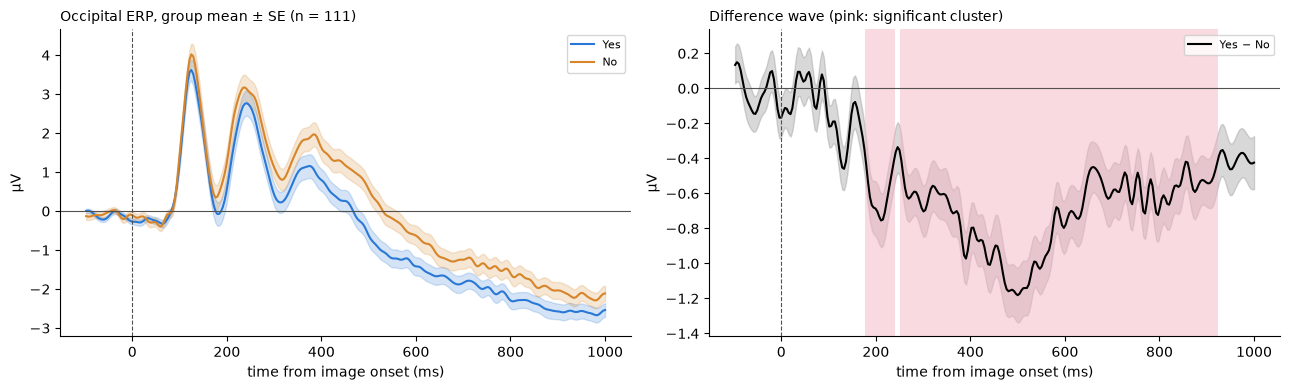

,from (ms),to (ms),mass,p,significant
1,178,240,-67.0207,0.0043,True
2,252,924,-816.4904,0.0001,True


In [4]:
ERP_YES = np.array([DATA[s]["erp_yes"] for s in SUBJECTS])
ERP_NO = np.array([DATA[s]["erp_no"] for s in SUBJECTS])
ERP_DIFF = ERP_YES - ERP_NO
w = (SHORT_MS >= 150) & (SHORT_MS <= 600)
mean_diff = ERP_DIFF[:, w].mean(axis=1)
t, p = stats.ttest_1samp(mean_diff, 0)
print(f"Yes − No, 150–600 ms: {mean_diff.mean():+.2f} µV | negative in {(mean_diff < 0).sum()}/{len(mean_diff)} | t = {t:.2f}, p = {p:.1e}")
erp_clusters = cluster_test(ERP_DIFF, SHORT_MS, two_sided=True)
print("significant clusters (ms):", spans(erp_clusters))
SUMMARY.append({"step": "1. ERP occipital", "result": f"Yes − No = {mean_diff.mean():+.2f} µV (150–600 ms)",
                "n": f"{(mean_diff < 0).sum()}/{len(mean_diff)} negative", "p": p, "when (ms)": spans(erp_clusters)})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for data, label, colour in [(ERP_YES, "Yes", "#2a78d6"), (ERP_NO, "No", "#d6852a")]:
    m, se = data.mean(0), data.std(0, ddof=1) / np.sqrt(len(data))
    axes[0].plot(SHORT_MS, m, color=colour, label=label)
    axes[0].fill_between(SHORT_MS, m - se, m + se, color=colour, alpha=0.2)
m, se = ERP_DIFF.mean(0), ERP_DIFF.std(0, ddof=1) / np.sqrt(len(ERP_DIFF))
axes[1].plot(SHORT_MS, m, color="black", label="Yes − No")
axes[1].fill_between(SHORT_MS, m - se, m + se, color="grey", alpha=0.3)
shade(axes[1], erp_clusters)
axes[0].set_title(f"Occipital ERP, group mean ± SE (n = {len(SUBJECTS)})", loc="left", fontsize=10)
axes[1].set_title("Difference wave (pink: significant cluster)", loc="left", fontsize=10)
for ax in axes:
    ax.axhline(0, color="#52514e", lw=0.8); ax.axvline(0, color="#52514e", lw=0.8, ls="--")
    ax.set_xlabel("time from image onset (ms)"); ax.set_ylabel("µV"); ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{NAME}_final_1_erp.png", dpi=130); plt.show()
erp_clusters[erp_clusters.significant].round(4)

## 2. Can the answer be predicted inside each participant? (article's decoding, as a classification)

For each participant: an LDA with shrinkage (Rafaela's choice after her benchmark of 8 classifiers) at **each time point**, trained on 4/5 of the images and tested on the other 1/5 (5-fold, grouped by image: the 3 views of an image stay together), on all 360 image trials. Score: AUC. Chance: the same with the answers shuffled between images. Tests: the **200–500 ms** window fixed in advance (t-tests), and the cluster test over time (real − shuffled).

200–500 ms: AUC = 0.523 (above 0.5 in 77/111), shuffled = 0.505; p vs 0.5 = 9.8e-12, p vs shuffled = 6.4e-06


significant clusters, real vs shuffled (ms): 205–229, 295–416, 451–486, 494–736, 740–783, 791–842, 846–893, 896–963, 979–1002


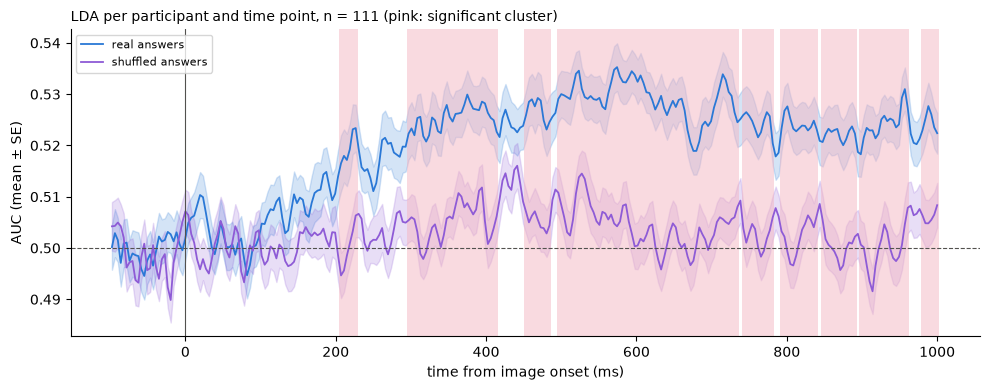

In [5]:
LDA_REAL = np.array([DATA[s]["lda_real"] for s in SUBJECTS])
LDA_SHUF = np.array([DATA[s]["lda_shuffled"] for s in SUBJECTS])
w = (SHORT_MS >= 200) & (SHORT_MS <= 500)
win_real, win_shuf = LDA_REAL[:, w].mean(1), LDA_SHUF[:, w].mean(1)
p_05 = stats.ttest_1samp(win_real, 0.5, alternative="greater").pvalue
p_sh = stats.ttest_rel(win_real, win_shuf, alternative="greater").pvalue
print(f"200–500 ms: AUC = {win_real.mean():.3f} (above 0.5 in {(win_real > 0.5).sum()}/{len(win_real)}), "
      f"shuffled = {win_shuf.mean():.3f}; p vs 0.5 = {p_05:.1e}, p vs shuffled = {p_sh:.1e}")
lda_clusters = cluster_test(LDA_REAL - LDA_SHUF, SHORT_MS)
print("significant clusters, real vs shuffled (ms):", spans(lda_clusters))
SUMMARY.append({"step": "2. LDA within each participant", "result": f"AUC = {win_real.mean():.3f} (200–500 ms)",
                "n": f"{(win_real > 0.5).sum()}/{len(win_real)} above 0.5", "p": p_sh, "when (ms)": spans(lda_clusters)})

fig, ax = plt.subplots(figsize=(10, 4))
for curves, label, colour in [(LDA_REAL, "real answers", "#2a78d6"), (LDA_SHUF, "shuffled answers", "#8e5bd6")]:
    m, se = curves.mean(0), curves.std(0, ddof=1) / np.sqrt(len(curves))
    ax.plot(SHORT_MS, m, color=colour, lw=1.3, label=label)
    ax.fill_between(SHORT_MS, m - se, m + se, color=colour, alpha=0.2)
shade(ax, lda_clusters)
ax.axhline(0.5, color="#52514e", lw=0.8, ls="--"); ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("time from image onset (ms)"); ax.set_ylabel("AUC (mean ± SE)")
ax.set_title(f"LDA per participant and time point, n = {len(SUBJECTS)} (pink: significant cluster)", loc="left", fontsize=10)
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{NAME}_final_2_lda.png", dpi=130); plt.show()

## 3. Can it be predicted for a **new** participant? The general Yes − No pattern (our method)

**Idea.** One participant's Yes − No difference is very noisy (120 images). If the EEG of a "Yes" looks roughly the same in different people (after a z-score per participant), averaging the Yes − No patterns of **many** participants removes the noise.

**Method.**
1. For every participant, on the **training images**: pattern = mean EEG of the Yes trials − mean EEG of the No trials (64 electrodes × 10 ms windows).
2. For the left-out participant: general pattern = mean of the patterns of **all the other** participants.
3. Each of his trials on the **test images** gets a score = similarity (dot product) with the general pattern; high → "Yes". AUC per 10 ms window, and for the whole period (sum over the 100 ms windows of the period).
4. Images in 5 folds, repeated with 10 different splits; every participant is left out once.

No fitted classifier, no hyperparameter. **Own** = the same method with the participant's own pattern (within-subject, 5-fold over his trials), as a comparison. Chance: answers shuffled within each participant (all participants), once.

**Periods:** image (while looking at the food), question (after "Tasty?" appears), response (before the key press; the Yes/No keys were randomised, so this is not the hand movement).

In [6]:
def pattern(X, y):
    return np.nanmean(X[y == 1], axis=0) - np.nanmean(X[y == 0], axis=0)


def period_mask(period):
    w = PERIODS[period][1]
    return (STARTS[period] >= w[0][0]) & (STARTS[period] + WIN <= w[-1][1])


def scores(X, template, mask):
    per_window = np.einsum("icw,cw->iw", X, template)
    return np.concatenate([per_window, per_window[:, mask].sum(axis=1, keepdims=True)], axis=1)


def general_template(period, labels, n_train=None, repeats=N_REPEATS, seed=0):
    """New participant + new images. {subject: AUC per window + whole period (last)}, averaged over the folds."""
    mask = period_mask(period)
    rng = np.random.default_rng(seed)
    result = {s: [] for s in SUBJECTS}
    for r in range(repeats):
        for train_img, test_img in KFold(5, shuffle=True, random_state=seed + r).split(IMAGES):
            P = {}
            for s in SUBJECTS:
                tr = np.isin(DATA[s]["img"], train_img) & DATA[s]["valid"][period]
                P[s] = pattern(DATA[s]["X"][period][tr], labels[s][tr])
            total = np.sum(list(P.values()), axis=0)
            for t in SUBJECTS:
                if n_train is None:
                    template = (total - P[t]) / (len(SUBJECTS) - 1)
                else:
                    others = [s for s in SUBJECTS if s != t]
                    template = np.mean([P[s] for s in rng.choice(others, n_train, replace=False)], axis=0)
                te = np.isin(DATA[t]["img"], test_img) & DATA[t]["valid"][period]
                result[t].append(auc_columns(labels[t][te], scores(DATA[t]["X"][period][te], template, mask)))
    return {s: np.nanmean(v, axis=0) for s, v in result.items()}


def own_template(period, labels, repeats=N_REPEATS, seed=0):
    mask = period_mask(period)
    result = {}
    for s in SUBJECTS:
        v = np.flatnonzero(DATA[s]["valid"][period])
        X, y = DATA[s]["X"][period][v], labels[s][v]
        aucs = []
        for r in range(repeats):
            for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed + r).split(X, y):
                aucs.append(auc_columns(y[te], scores(X[te], pattern(X[tr], y[tr]), mask)))
        result[s] = np.nanmean(aucs, axis=0)
    return result


REAL = {s: DATA[s]["y"] for s in SUBJECTS}
rng = np.random.default_rng(12345)
SHUFFLED = {s: rng.permutation(DATA[s]["y"]) for s in SUBJECTS}
METHODS = {"general": general_template, "own": own_template}

RES = {}
start = time.time()
for period in PERIODS:
    for method, fn in METHODS.items():
        for lab, labels in [("real", REAL), ("shuffled", SHUFFLED)]:
            out = fn(period, labels)
            RES[(period, method, lab)] = np.array([out[s] for s in SUBJECTS])
print(f"done ({time.time() - start:.0f} s)")

done (54 s)


### 3a. Whole-period score

In [7]:
rows = []
for period in PERIODS:
    for method in METHODS:
        real, shuf = RES[(period, method, "real")][:, -1], RES[(period, method, "shuffled")][:, -1]
        rows.append({"period": period, "pattern": method, "AUC": real.mean(), "AUC shuffled": shuf.mean(),
                     "n above 0.5": f"{(real > 0.5).sum()}/{len(real)}",
                     "p (vs shuffled)": stats.ttest_rel(real, shuf, alternative="greater").pvalue})
    g, o = RES[(period, "general", "real")][:, -1], RES[(period, "own", "real")][:, -1]
    rows.append({"period": period, "pattern": "general − own", "AUC": (g - o).mean(),
                 "n above 0.5": f"{(g > o).sum()}/{len(g)} general better", "p (vs shuffled)": stats.ttest_rel(g, o).pvalue})
template_summary = pd.DataFrame(rows)
template_summary.round(4)

,period,pattern,AUC,AUC shuffled,n above 0.5,p (vs shuffled)
0,image,general,0.5546,0.5079,87/111,0.0000
1,image,own,0.5375,0.4917,76/111,0.0000
2,image,general − own,0.0171,NaN,77/111 general better,0.0046
3,question,general,0.5453,0.5054,81/111,0.0000
4,question,own,0.5408,0.4977,81/111,0.0000
5,question,general − own,0.0045,NaN,67/111 general better,0.5934
6,response,general,0.5349,0.4932,75/111,0.0000
7,response,own,0.5439,0.4901,80/111,0.0000
8,response,general − own,-0.0091,NaN,50/111 general better,0.3491


### 3b. When does it work? Cluster test (real − shuffled), 10 ms windows

image     general  significant clusters (ms): 260–1000


image     own      significant clusters (ms): 240–290, 410–530, 660–710, 750–840, 860–890, 900–930


question  general  significant clusters (ms): 370–440, 480–560, 810–840, 900–970, 1100–1230, 1250–1300, 1310–1340, 1440–1470


question  own      significant clusters (ms): 730–760, 890–980, 1080–1130, 1170–1210, 1460–1500


response  general  significant clusters (ms): -800–-760, -620–-570, -170–-10, 0–80


response  own      significant clusters (ms): -510–-420, -340–-180, -170–-140, -130–60


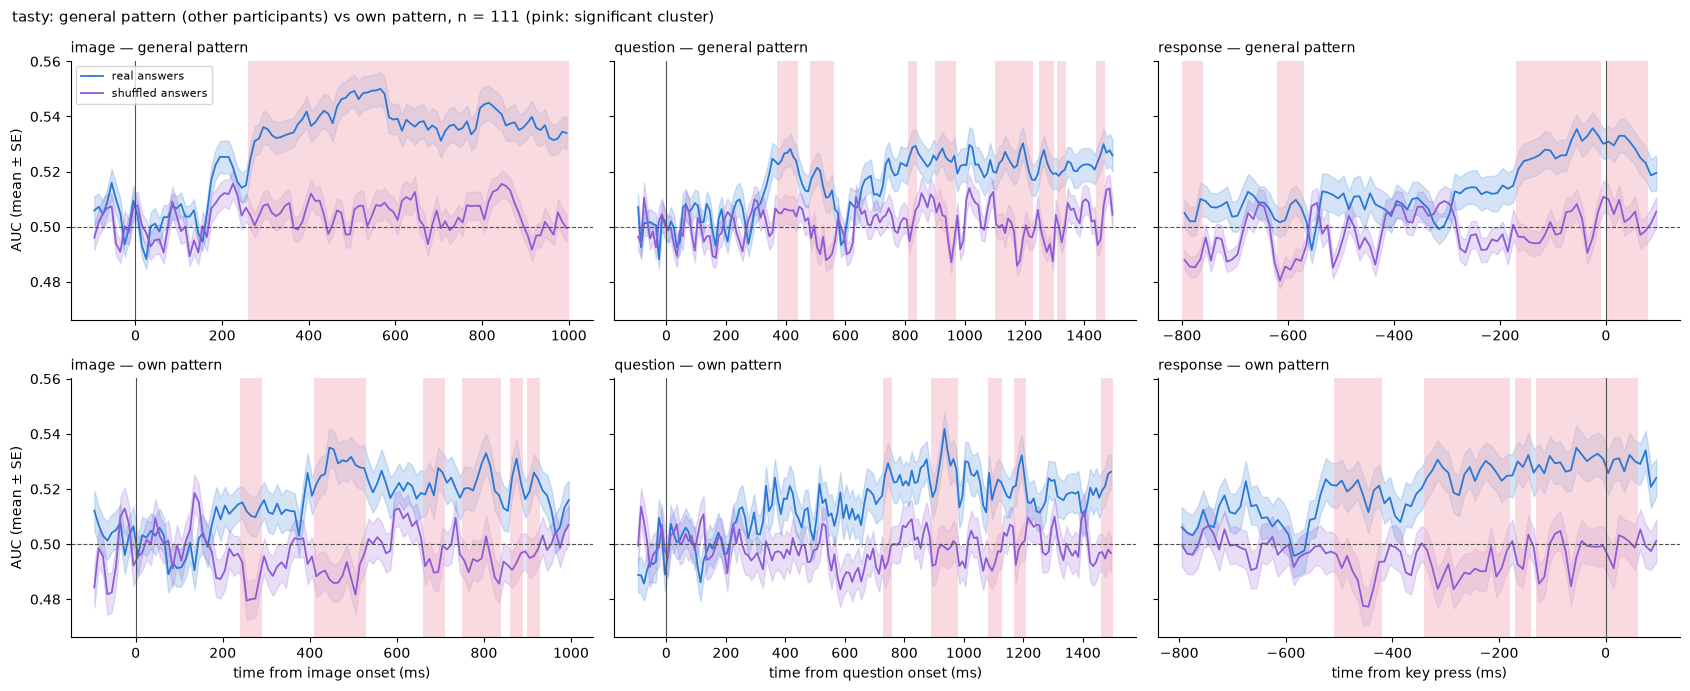

In [8]:
TEMPLATE_CLUSTERS = {}
for period in PERIODS:
    for method in METHODS:
        d = RES[(period, method, "real")][:, :-1] - RES[(period, method, "shuffled")][:, :-1]
        TEMPLATE_CLUSTERS[(period, method)] = cluster_test(d, CENTRES[period])
        print(f"{period:<9} {method:<8} significant clusters (ms): {spans(TEMPLATE_CLUSTERS[(period, method)])}")
for period in PERIODS:
    g = RES[(period, "general", "real")][:, -1]
    SUMMARY.append({"step": f"3. general pattern, {period}", "result": f"AUC = {g.mean():.3f} (whole period)",
                    "n": f"{(g > 0.5).sum()}/{len(g)} above 0.5",
                    "p": stats.ttest_rel(g, RES[(period, "general", "shuffled")][:, -1], alternative="greater").pvalue,
                    "when (ms)": spans(TEMPLATE_CLUSTERS[(period, "general")])})

XLABEL = {"image": "time from image onset (ms)", "question": "time from question onset (ms)", "response": "time from key press (ms)"}
fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharey=True)
for row, method in enumerate(METHODS):
    for col, period in enumerate(PERIODS):
        ax = axes[row, col]
        for lab, colour in [("real", "#2a78d6"), ("shuffled", "#8e5bd6")]:
            z = RES[(period, method, lab)][:, :-1]
            m, se = z.mean(0), z.std(0, ddof=1) / np.sqrt(len(z))
            ax.plot(CENTRES[period], m, color=colour, lw=1.3, label=f"{lab} answers")
            ax.fill_between(CENTRES[period], m - se, m + se, color=colour, alpha=0.2)
        shade(ax, TEMPLATE_CLUSTERS[(period, method)])
        ax.axhline(0.5, color="#52514e", lw=0.8, ls="--"); ax.axvline(0, color="#52514e", lw=0.8)
        ax.set_title(f"{period} — {method} pattern", loc="left", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        if row == 1:
            ax.set_xlabel(XLABEL[period])
    axes[row, 0].set_ylabel("AUC (mean ± SE)")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"{NAME}: general pattern (other participants) vs own pattern, n = {len(SUBJECTS)} (pink: significant cluster)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(f"{NAME}_final_3_template.png", dpi=130); plt.show()

### 3c. Learning curve: how many participants does the general pattern need?

Whole-period AUC when the general pattern is learnt from *k* random other participants (3 image splits per point). Our first analyses had only 6 participants, i.e. k = 5.

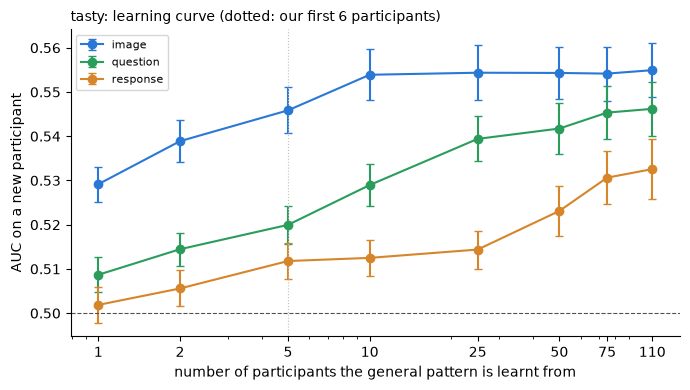

period,image,question,response
k,,,
1,0.5292,0.5087,0.5019
2,0.5389,0.5145,0.5056
5,0.5459,0.5200,0.5118
10,0.5539,0.5290,0.5125
25,0.5544,0.5394,0.5144
50,0.5543,0.5417,0.5231
75,0.5542,0.5453,0.5306
110,0.5549,0.5462,0.5326


In [9]:
K = [1, 2, 5, 10, 25, 50, 75, len(SUBJECTS) - 1]
curve = []
for period in PERIODS:
    for k in K:
        out = general_template(period, REAL, n_train=None if k == len(SUBJECTS) - 1 else k, repeats=3, seed=100)
        a = np.array([out[s][-1] for s in SUBJECTS])
        curve.append({"period": period, "k": k, "AUC": a.mean(), "SE": a.std(ddof=1) / np.sqrt(len(a))})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7, 4))
for period, colour in zip(PERIODS, ["#2a78d6", "#2a9d5c", "#d6852a"]):
    c = curve[curve.period == period]
    ax.errorbar(c.k, c.AUC, yerr=c.SE, marker="o", color=colour, label=period, capsize=3)
ax.axhline(0.5, color="#52514e", lw=0.8, ls="--"); ax.axvline(5, color="#c3c2b7", lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xticks(K, [str(k) for k in K])
ax.set_xlabel("number of participants the general pattern is learnt from"); ax.set_ylabel("AUC on a new participant")
ax.set_title(f"{NAME}: learning curve (dotted: our first 6 participants)", loc="left", fontsize=10)
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{NAME}_final_3_learning_curve.png", dpi=130); plt.show()
curve.pivot(index="k", columns="period", values="AUC").round(4)

## 4. Does the EEG read the judgment, or just the image?

The EEG also reflects **what the image looks like**, and the foods that people answer "Yes" to share visual properties. The article points this out (*"vegetables make up a large proportion of foods that are green and at the same time tend to be judged as healthy"*; low-level features modulate early responses, P1/N1), provides luminance and contrast of each image and the images themselves (OSF, folder `stimuli/`), and **encourages users to control for them**; it does not do it in its own analyses.

The model never sees the images: they are only used to **check** that the EEG decoding is not a visual shortcut.

**4a. Image features.** Luminance and RMS contrast (from the article); computed from each image (food pixels only, the white background is excluded): mean red, green, blue, saturation, greenness G − (R + B)/2, colourfulness (Hasler & Süsstrunk), food area, edge density (visual complexity). Reference: how well these features alone (no EEG) predict the answer.

In [10]:
# 10 visual features per image (luminance, contrast, colours, food area, edges), z-scored; see outils.py
IMG = load_image_features().loc[IMAGES]
FEATURES = list(IMG.columns)
Z_IMG = IMG.values

YMAT = np.full((len(SUBJECTS), len(IMAGES)), np.nan)
for k, s in enumerate(SUBJECTS):
    YMAT[k, DATA[s]["img"]] = DATA[s]["y"]
display(pd.Series({f: stats.spearmanr(IMG[f], np.nanmean(YMAT, axis=0))[0] for f in FEATURES},
                  name="Spearman r with the share of Yes").round(3).to_frame().T)

feature_auc = np.array([auc_columns(DATA[s]["y"], cross_val_predict(
    LogisticRegression(C=1.0), Z_IMG[DATA[s]["img"]], DATA[s]["y"], cv=StratifiedKFold(5, shuffle=True, random_state=0),
    method="decision_function")[:, None])[0] for s in SUBJECTS])
print(f"image features alone (no EEG) -> answer: AUC = {feature_auc.mean():.3f} (above 0.5 in {(feature_auc > 0.5).sum()}/{len(feature_auc)})")
SUMMARY.append({"step": "4. reference: image features only (no EEG)", "result": f"AUC = {feature_auc.mean():.3f}",
                "n": f"{(feature_auc > 0.5).sum()}/{len(feature_auc)} above 0.5", "p": np.nan, "when (ms)": ""})

,luminance,contrast,red,green,blue,saturation,greenness,colourfulness,food area,edge density
Spearman r with the share of Yes,0.139,-0.017,0.208,-0.156,-0.332,0.421,-0.148,0.461,-0.231,0.046


image features alone (no EEG) -> answer: AUC = 0.691 (above 0.5 in 106/111)


**4b. The controls**, on the out-of-fold scores of the general pattern (same procedure as step 3, every test trial's score kept):

- **Visual control:** for each participant, a linear regression *EEG ~ image features* is fitted on his **training images** (no answers used); its prediction is removed from all his trials before the pattern is learnt and the test trials are scored.
- **Consensus** of an image for a participant = share of the **other** participants who answered "Yes". It summarises everything that comes from the image (colour, shape, type of food...).
    - **Disagreement trials:** only the images where the participant answers against the majority of the others. A pattern that reads the image follows the majority → AUC **below** 0.5; one that reads the participant's own judgment → **above** 0.5.
    - **Beyond consensus:** per participant, logistic regression *answer ~ logit(consensus) + EEG score*; is the EEG coefficient larger than with shuffled answers, across participants? This uses all trials (more power than the disagreement trials).

In [11]:
def trial_scores(period, labels, visual_control, repeats=N_REPEATS, seed=0):
    mask = period_mask(period)
    out = {s: np.zeros((len(DATA[s]["y"]), len(STARTS[period]) + 1)) for s in SUBJECTS}
    for r in range(repeats):
        for train_img, test_img in KFold(5, shuffle=True, random_state=seed + r).split(IMAGES):
            P, X_test, test_idx = {}, {}, {}
            for s in SUBJECTS:
                X, v, img = DATA[s]["X"][period], DATA[s]["valid"][period], DATA[s]["img"]
                tr, te = np.isin(img, train_img) & v, np.isin(img, test_img) & v
                if visual_control:
                    Z = np.column_stack([np.ones(len(img)), Z_IMG[img]])
                    flat = X.reshape(len(X), -1)
                    beta = np.linalg.lstsq(Z[tr], flat[tr], rcond=None)[0]
                    X = (flat - Z @ beta).reshape(X.shape)
                P[s] = pattern(X[tr], labels[s][tr])
                X_test[s], test_idx[s] = X[te], np.flatnonzero(te)
            total = np.sum(list(P.values()), axis=0)
            for t in SUBJECTS:
                out[t][test_idx[t]] += scores(X_test[t], (total - P[t]) / (len(SUBJECTS) - 1), mask) / repeats
    for s in SUBJECTS:
        out[s][~DATA[s]["valid"][period]] = np.nan
    return out


def consensus_of(k):
    return np.nanmean(np.delete(YMAT, k, axis=0), axis=0)[DATA[SUBJECTS[k]]["img"]]


def evaluate(sc, labels, period):
    all_auc, dis_auc, coef, n_dis = [], [], [], []
    for k, s in enumerate(SUBJECTS):
        v = DATA[s]["valid"][period]
        y, x, c = labels[s][v], sc[s][v], consensus_of(k)[v]
        all_auc.append(auc_columns(y, x))
        dis = ((y == 1) != (c > 0.5)) & (c != 0.5)
        n_dis.append(dis.sum())
        dis_auc.append(auc_columns(y[dis], x[dis]) if dis.sum() >= 4 else np.full(x.shape[1], np.nan))
        lc = np.log(np.clip(c, 0.02, 0.98) / (1 - np.clip(c, 0.02, 0.98)))
        e = x[:, -1]
        Z = np.column_stack([(lc - lc.mean()) / lc.std(), (e - e.mean()) / (e.std() + 1e-12)])
        coef.append(LogisticRegression(C=1e6, max_iter=1000).fit(Z, y).coef_[0, 1])
    return np.array(all_auc), np.array(dis_auc), np.array(coef), np.array(n_dis)


EVAL = {}
start = time.time()
for period in PERIODS:
    for control in [False, True]:
        for lab, labels in [("real", REAL), ("shuffled", SHUFFLED)]:
            EVAL[(period, control, lab)] = evaluate(trial_scores(period, labels, control), labels, period)
print(f"done ({time.time() - start:.0f} s)")

rows = []
for period in PERIODS:
    for control in [False, True]:
        a, d, b, n = EVAL[(period, control, "real")]
        a0, _, b0, _ = EVAL[(period, control, "shuffled")]
        keep = ~np.isnan(d[:, -1])
        rows.append({"period": period, "visual control": "yes" if control else "no",
                     "AUC all trials": a[:, -1].mean(),
                     "p all (vs shuffled)": stats.ttest_rel(a[:, -1], a0[:, -1], alternative="greater").pvalue,
                     "AUC disagreement": np.nanmean(d[:, -1]), "disagreement images / participant": n.mean(),
                     "p disagr. (vs 0.5)": stats.ttest_1samp(d[keep, -1], 0.5, alternative="greater").pvalue,
                     "EEG coef beyond consensus": b.mean(),
                     "p coef (vs shuffled)": stats.ttest_rel(b, b0, alternative="greater").pvalue})
controls = pd.DataFrame(rows)
for _, r in controls[controls["visual control"] == "yes"].iterrows():
    SUMMARY.append({"step": f"4. after visual control, {r.period}", "result": f"AUC = {r['AUC all trials']:.3f}",
                    "n": "", "p": r["p all (vs shuffled)"], "when (ms)": ""})
    SUMMARY.append({"step": f"4. beyond consensus (+ visual control), {r.period}",
                    "result": f"coef = {r['EEG coef beyond consensus']:+.3f}; disagreement AUC = {r['AUC disagreement']:.3f}",
                    "n": "", "p": r["p coef (vs shuffled)"], "when (ms)": ""})
controls.round(4)

done (365 s)


,period,visual control,AUC all trials,p all (vs shuffled),AUC disagreement,disagreement images / participant,p disagr. (vs 0.5),EEG coef beyond consensus,p coef (vs shuffled)
0,image,no,0.5536,0.0000,0.4338,26.4054,1.0000,0.0401,0.4260
1,image,yes,0.5265,0.0066,0.4524,26.4054,0.9983,0.0216,0.6538
2,question,no,0.5442,0.0000,0.4904,26.4054,0.7051,0.1190,0.0039
3,question,yes,0.5293,0.0010,0.4997,26.4054,0.5061,0.1026,0.0067
4,response,no,0.5358,0.0000,0.4940,24.1622,0.6242,0.1180,0.0005
5,response,yes,0.5271,0.0000,0.5013,24.1622,0.4712,0.1019,0.0012


**4c. When does the signal survive the controls?** Cluster tests: all trials after the visual control (real − shuffled), and disagreement trials (− 0.5).

image     visual control no   all trials: 260–1000  |  disagreement: none


image     visual control yes  all trials: 470–500, 900–940  |  disagreement: none


question  visual control no   all trials: 380–420, 530–560, 810–840, 940–970, 1110–1220, 1250–1300, 1440–1470  |  disagreement: none


question  visual control yes  all trials: 1130–1200, 1250–1300, 1440–1470  |  disagreement: none


response  visual control no   all trials: -620–-570, -170–-10, 0–80  |  disagreement: none


response  visual control yes  all trials: -280–-250, -160–-110, -70–-10  |  disagreement: none


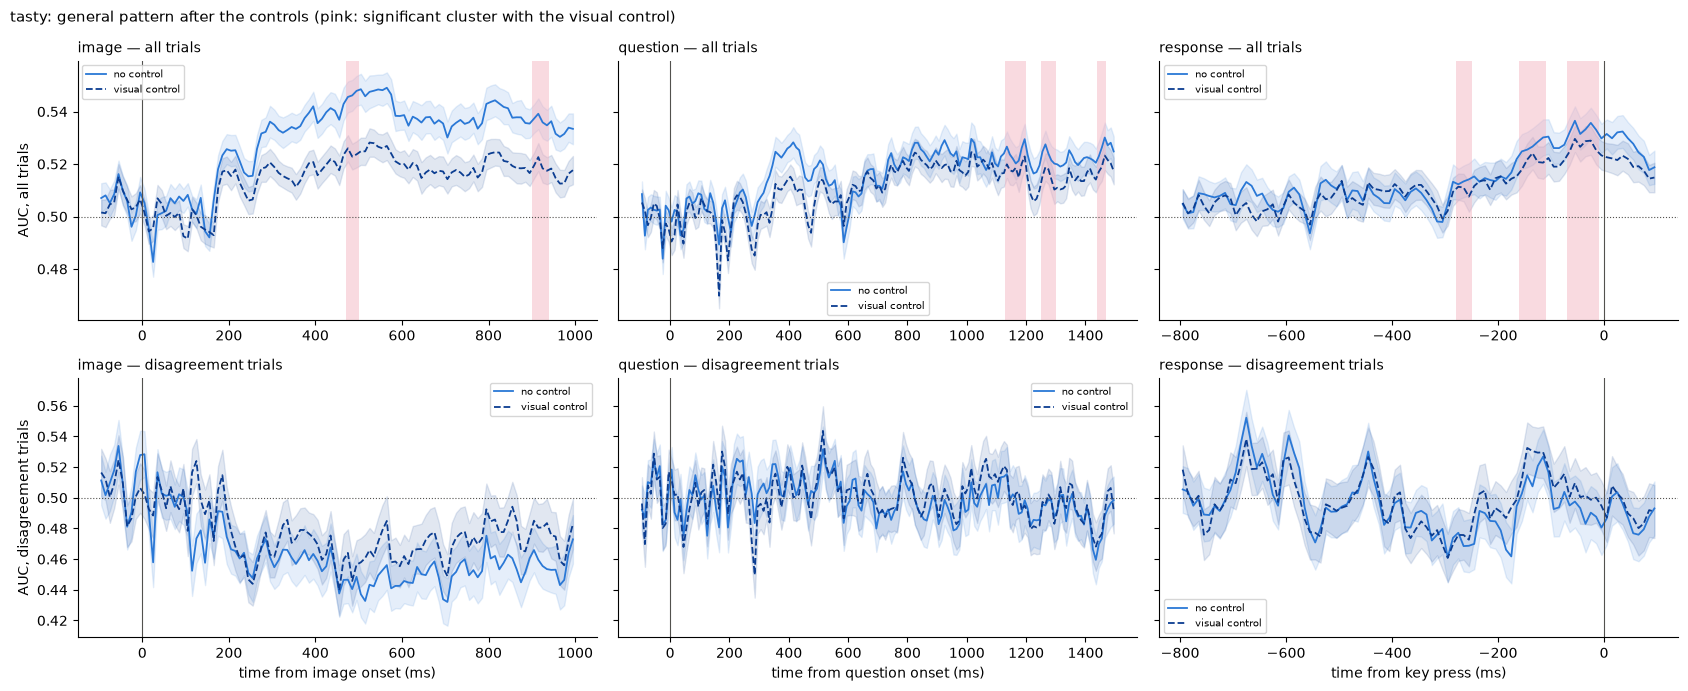

In [12]:
CONTROL_CLUSTERS = {}
for period in PERIODS:
    for control in [False, True]:
        a, d, _, _ = EVAL[(period, control, "real")]
        a0 = EVAL[(period, control, "shuffled")][0]
        CONTROL_CLUSTERS[(period, control, "all")] = cluster_test(a[:, :-1] - a0[:, :-1], CENTRES[period])
        CONTROL_CLUSTERS[(period, control, "disagreement")] = cluster_test(d[:, :-1] - 0.5, CENTRES[period])
        print(f"{period:<9} visual control {'yes' if control else 'no ':<3}  all trials: {spans(CONTROL_CLUSTERS[(period, control, 'all')])}"
              f"  |  disagreement: {spans(CONTROL_CLUSTERS[(period, control, 'disagreement')])}")

fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharey="row")
for col, period in enumerate(PERIODS):
    for row, (kind, idx) in enumerate([("all", 0), ("disagreement", 1)]):
        ax = axes[row, col]
        for control, colour, ls in [(False, "#2a78d6", "-"), (True, "#0b3d91", "--")]:
            z = EVAL[(period, control, "real")][idx][:, :-1]
            z = z[~np.isnan(z).any(axis=1)]
            m, se = z.mean(0), z.std(0, ddof=1) / np.sqrt(len(z))
            ax.plot(CENTRES[period], m, color=colour, ls=ls, lw=1.3, label="visual control" if control else "no control")
            ax.fill_between(CENTRES[period], m - se, m + se, color=colour, alpha=0.12)
        shade(ax, CONTROL_CLUSTERS[(period, True, kind)])
        ax.axhline(0.5, color="#52514e", lw=0.8, ls=":"); ax.axvline(0, color="#52514e", lw=0.8)
        ax.set_title(f"{period} — {kind} trials", loc="left", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=7)
        if row == 1:
            ax.set_xlabel(XLABEL[period])
    axes[0, 0].set_ylabel("AUC, all trials"); axes[1, 0].set_ylabel("AUC, disagreement trials")
fig.suptitle(f"{NAME}: general pattern after the controls (pink: significant cluster with the visual control)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(f"{NAME}_final_4_controls.png", dpi=130); plt.show()

## 5. Summary

In [13]:
summary = pd.DataFrame(SUMMARY)
summary.to_csv(f"{NAME}_final_summary.csv", index=False)
template_summary.to_csv(f"{NAME}_final_template.csv", index=False)
controls.to_csv(f"{NAME}_final_controls.csv", index=False)
curve.to_csv(f"{NAME}_final_learning_curve.csv", index=False)
pd.concat({**{f"ERP": erp_clusters, "LDA": lda_clusters},
           **{f"template {p} {m}": c for (p, m), c in TEMPLATE_CLUSTERS.items()},
           **{f"control {p} {'visual' if v else 'none'} {k}": c for (p, v, k), c in CONTROL_CLUSTERS.items()}},
          names=["analysis"]).to_csv(f"{NAME}_final_clusters.csv")
pd.DataFrame({"LDA 200–500 ms": win_real, "ERP Yes−No 150–600 ms": mean_diff,
              **{f"general {p}": RES[(p, "general", "real")][:, -1] for p in PERIODS},
              **{f"own {p}": RES[(p, "own", "real")][:, -1] for p in PERIODS}}, index=SUBJECTS).to_csv(f"{NAME}_final_per_subject.csv")
pd.set_option("display.max_colwidth", 120)
summary.style.format({"p": lambda v: "" if pd.isna(v) else f"{v:.1e}"})

,step,result,n,p,when (ms)
0,1. ERP occipital,Yes − No = -0.76 µV (150–600 ms),84/111 negative,7.3e-11,"178–240, 252–924"
1,2. LDA within each participant,AUC = 0.523 (200–500 ms),77/111 above 0.5,6.4e-06,"205–229, 295–416, 451–486, 494–736, 740–783, 791–842, 846–893, 896–963, 979–1002"
2,"3. general pattern, image",AUC = 0.555 (whole period),87/111 above 0.5,9.8e-09,260–1000
3,"3. general pattern, question",AUC = 0.545 (whole period),81/111 above 0.5,4.8e-06,"370–440, 480–560, 810–840, 900–970, 1100–1230, 1250–1300, 1310–1340, 1440–1470"
4,"3. general pattern, response",AUC = 0.535 (whole period),75/111 above 0.5,1.8e-06,"-800–-760, -620–-570, -170–-10, 0–80"
5,4. reference: image features only (no EEG),AUC = 0.691,106/111 above 0.5,,
6,"4. after visual control, image",AUC = 0.527,,6.6e-03,
7,"4. beyond consensus (+ visual control), image",coef = +0.022; disagreement AUC = 0.452,,6.5e-01,
8,"4. after visual control, question",AUC = 0.529,,9.9e-04,
9,"4. beyond consensus (+ visual control), question",coef = +0.103; disagreement AUC = 0.500,,6.7e-03,


**Conclusion.**

1. **ERP.** "Tasty = Yes" images give a more negative occipital ERP: −0.76 µV over 150–600 ms, negative in 84/111 participants (p = 7e-11). Significant clusters at 178–240 and 252–924 ms. The effect is larger than for healthy (−0.53 µV).
2. **LDA per participant.** AUC 0.523 over 200–500 ms (77/111 above 0.5; p = 6e-6 vs shuffled answers). Significant clusters from about 200 ms to 1000 ms.
3. **General template.** AUC 0.555 (image), 0.545 (question), 0.535 (response), all p < 0.0001. In the image period the general pattern beats the participant's own pattern (p = 0.005). The image-period learning curve saturates after only about 10 participants; the response curve is still rising.
4. **Controls.**
   - Image features alone predict "tasty" well (AUC 0.691). After removing them from the EEG, the signal **remains significant in all three periods** (image 0.527, question 0.529, response 0.527).
   - In the image period, the AUC on disagreement images is *below* 0.5 (0.434): early on, the EEG follows what most people think of the image, not the participant's own answer.
   - **At the question and the response, the EEG adds information beyond the consensus, even after the visual control** (question p = 0.007, response p = 0.001). **This is evidence of a personal judgment at decision time.**
5. **Consistency check (Appendix A).** The template values are identical to `tasty_test3_all_subjects` and the controls differ by at most 0.006 (10 repetitions here instead of 5). One participant (sub-046: 114 Yes / 6 No) is excluded for too few "No" answers.

## A. Check: same results as the separate notebooks?

The separate notebooks (`tasty_all_subjects`, `tasty_test3_all_subjects`, `tasty_test3_controls`) computed the same analyses. Differences come only from: (i) here, participants with a missing or duplicated answer keep their other images (the LDA notebook excluded them entirely); (ii) the controls used 5 image splits there, 10 here; (iii) random seeds of the permutations.

In [14]:
checks = []
def add(what, old_file, old_value, new_value):
    checks.append({"analysis": what, "separate notebook": old_file, "before": old_value, "final": new_value,
                   "difference": new_value - old_value})

if Path(f"{NAME}_all_subjects_window.csv").exists():
    old = pd.read_csv(f"{NAME}_all_subjects_window.csv")
    add("LDA AUC 200–500 ms", f"{NAME}_all_subjects", old["AUC 200–500 ms"].mean(), win_real.mean())
    common = old.set_index("subject")["AUC 200–500 ms"]
    new = pd.Series(win_real, index=SUBJECTS).loc[common.index]
    print(f"LDA, same participants ({len(common)}): correlation of the per-participant AUC = {np.corrcoef(common, new)[0, 1]:.3f}, "
          f"max |difference| = {np.abs(common - new).max():.4f}")
old = pd.read_csv(f"{NAME}_test3_all_subjects_summary.csv")
for period in PERIODS:
    for method, old_name in [("general", "general (other participants)"), ("own", "own (within-subject)")]:
        add(f"template {method}, {period}", f"{NAME}_test3_all_subjects",
            old[(old.period == period) & (old.method == old_name)].AUC.item(), RES[(period, method, "real")][:, -1].mean())
old = pd.read_csv(f"{NAME}_test3_controls_summary.csv")
for _, r in controls.iterrows():
    o = old[(old.period == r.period) & (old["visual control"] == r["visual control"])].iloc[0]
    for col in ["AUC all trials", "AUC disagreement", "EEG coef beyond consensus"]:
        add(f"{col}, {r.period}, visual control {r['visual control']}", f"{NAME}_test3_controls", o[col], r[col])
checks = pd.DataFrame(checks)
checks.round(4)

,analysis,separate notebook,before,final,difference
0,"template general, image",tasty_test3_all_subjects,0.5546,0.5546,0.0000
1,"template own, image",tasty_test3_all_subjects,0.5375,0.5375,0.0000
2,"template general, question",tasty_test3_all_subjects,0.5453,0.5453,0.0000
3,"template own, question",tasty_test3_all_subjects,0.5408,0.5408,0.0000
4,"template general, response",tasty_test3_all_subjects,0.5349,0.5349,0.0000
5,"template own, response",tasty_test3_all_subjects,0.5439,0.5439,0.0000
6,"AUC all trials, image, visual control no",tasty_test3_controls,0.5534,0.5536,0.0002
7,"AUC disagreement, image, visual control no",tasty_test3_controls,0.4350,0.4338,-0.0012
8,"EEG coef beyond consensus, image, visual control no",tasty_test3_controls,0.0398,0.0401,0.0003
9,"AUC all trials, image, visual control yes",tasty_test3_controls,0.5268,0.5265,-0.0003
